# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhamad Farhan
- **Email:** mhmdfarhan205@gmail.com
- **ID Dicoding:** farennxt

## Menentukan Pertanyaan Bisnis

**Pertanyaan Bisnis (Menggunakan Framework SMART):**

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata dan total penyewaan sepeda harian antara pengguna `casual` dan `registered` di setiap musim (*Spring, Summer, Fall, Winter*) selama periode 2011–2012, serta seberapa besar pertumbuhan *Year-over-Year* (YoY) penyewaan sepeda dari tahun 2011 ke 2012?
  - *Specific:* Membandingkan segmen pengguna `casual` vs `registered` berdasarkan musim dan tahun.
  - *Measurable:* Total penyewaan (`cnt`), rata-rata harian, dan persentase pertumbuhan YoY (%).
  - *Action-Oriented:* Menentukan periode musiman terbaik untuk kampanye konversi pengguna `casual` menjadi member `registered` dan alokasi armada.
  - *Relevant:* Pertumbuhan pengguna dan retensi member merupakan KPI utama layanan *bike-sharing*.
  - *Time-bound:* Periode historis 2011–2012.

- **Pertanyaan 2:** Pada jam berapa saja puncak permintaan (*peak hours*) penyewaan sepeda terjadi untuk pengguna `registered` dan `casual` pada hari kerja (*working day*) dibandingkan akhir pekan/hari libur (*weekend/holiday*) selama tahun 2011–2012?
  - *Specific:* Menganalisis pola jam (`hr` 0–23) berdasarkan tipe hari dan segmen pengguna.
  - *Measurable:* Rata-rata jumlah penyewaan per jam.
  - *Action-Oriented:* Menjadi dasar penjadwalan distribusi ulang sepeda (*rebalancing*) sebelum jam sibuk dan jadwal pemeliharaan armada di jam sepi.
  - *Relevant:* Ketersediaan sepeda pada jam puncak memengaruhi tingkat kepuasan dan utilisasi.
  - *Time-bound:* Periode historis 2011–2012.

- **Pertanyaan 3:** Seberapa besar penurunan rata-rata penyewaan sepeda per jam ketika kondisi cuaca memburuk (dari Cerah ke Berkabut hingga Hujan/Salju) dan bagaimana pengaruh kategori suhu terhadap volume penyewaan selama tahun 2011–2012?
  - *Specific:* Mengukur dampak kondisi cuaca (`weathersit`) dan suhu (`temp`) terhadap penyewaan per jam.
  - *Measurable:* Persentase penurunan rata-rata penyewaan per jam antar kategori cuaca.
  - *Action-Oriented:* Mendukung strategi operasional saat cuaca buruk (penyesuaian armada aktif dan perawatan komponen).
  - *Relevant:* Layanan transportasi terbuka sangat sensitif terhadap perubahan cuaca.
  - *Time-bound:* Periode historis 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan visualisasi agar konsisten dan mudah dibaca
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Data Wrangling

### Gathering Data

Pada tahap ini, kita memuat dua berkas dataset utama dari **Bike Sharing Dataset**, yaitu `day.csv` (agregasi harian) dan `hour.csv` (agregasi per jam), ke dalam DataFrame pandas.

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print(f"Ukuran day_df : {day_df.shape[0]} baris, {day_df.shape[1]} kolom")
print(f"Ukuran hour_df: {hour_df.shape[0]} baris, {hour_df.shape[1]} kolom")

display(day_df.head())
display(hour_df.head())

Ukuran day_df : 731 baris, 16 kolom
Ukuran hour_df: 17379 baris, 17 kolom


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset berhasil dimuat dengan lengkap: `day_df` berisi **731 baris** (2 tahun penuh, 2011–2012 termasuk tahun kabisat 2012) dan 16 kolom.
- `hour_df` berisi **17.379 baris** dan 17 kolom (memiliki kolom tambahan `hr` untuk jam 0–23).
- Kedua tabel memiliki struktur kolom yang konsisten mencakup tanggal (`dteday`), atribut waktu (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`), kondisi cuaca (`weathersit`, `temp`, `atemp`, `hum`, `windspeed`), serta jumlah penyewaan (`casual`, `registered`, `cnt`).

### Assessing Data

#### Memeriksa Tipe Data, Missing Values, Duplikasi, dan Anomali Nilai

In [3]:
print("=== INFO day_df ===")
day_df.info()
print("\n=== INFO hour_df ===")
hour_df.info()

print("\nMissing values day_df :", day_df.isnull().sum().sum())
print("Missing values hour_df:", hour_df.isnull().sum().sum())
print("Duplikat day_df       :", day_df.duplicated().sum())
print("Duplikat hour_df      :", hour_df.duplicated().sum())

=== INFO day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== INFO hour_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1

In [4]:
print("=== Statistik Deskriptif day_df ===")
display(day_df.describe().T[["count", "mean", "std", "min", "50%", "max"]])

print("\n=== Statistik Deskriptif hour_df ===")
display(hour_df.describe().T[["count", "mean", "std", "min", "50%", "max"]])

# Cek nilai tidak wajar (inaccurate value) & konsistensi penjumlahan
print("\nPengecekan Anomali:")
print("- day_df dengan hum == 0          :", (day_df["hum"] == 0).sum())
print("- hour_df dengan hum == 0         :", (hour_df["hum"] == 0).sum())
print("- hour_df dengan windspeed == 0   :", (hour_df["windspeed"] == 0).sum())
print("- day_df casual+registered != cnt :", (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum())
print("- hour_df casual+registered != cnt:", (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum())

# Cek outlier menggunakan metode IQR pada kolom cnt dan casual
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    for col in ["casual", "registered", "cnt"]:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
        print(f"- Outlier IQR {name}.{col}: {n_out} baris")

=== Statistik Deskriptif day_df ===

=== Statistik Deskriptif hour_df ===

Pengecekan Anomali:
- day_df dengan hum == 0          : 1
- hour_df dengan hum == 0         : 22
- hour_df dengan windspeed == 0   : 2180
- day_df casual+registered != cnt : 0
- hour_df casual+registered != cnt: 0
- Outlier IQR day_df.casual: 44 baris
- Outlier IQR day_df.registered: 0 baris
- Outlier IQR day_df.cnt: 0 baris
- Outlier IQR hour_df.casual: 1192 baris
- Outlier IQR hour_df.registered: 680 baris
- Outlier IQR hour_df.cnt: 505 baris


,count,mean,std,min,50%,max
instant,731.0,366.000000,211.165812,1.000000,366.000000,731.000000
season,731.0,2.496580,1.110807,1.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,7.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,1.000000
...,...,...,...,...,...,...
hum,731.0,0.627894,0.142429,0.000000,0.626667,0.972500
windspeed,731.0,0.190486,0.077498,0.022392,0.180975,0.507463
casual,731.0,848.176471,686.622488,2.000000,713.000000,3410.000000
registered,731.0,3656.172367,1560.256377,20.000000,3662.000000,6946.000000


,count,mean,std,min,50%,max
instant,17379.0,8690.000000,5017.029500,1.0,8690.000,17379.0000
season,17379.0,2.501640,1.106918,1.0,3.000,4.0000
yr,17379.0,0.502561,0.500008,0.0,1.000,1.0000
mnth,17379.0,6.537775,3.438776,1.0,7.000,12.0000
hr,17379.0,11.546752,6.914405,0.0,12.000,23.0000
...,...,...,...,...,...,...
hum,17379.0,0.627229,0.192930,0.0,0.630,1.0000
windspeed,17379.0,0.190098,0.122340,0.0,0.194,0.8507
casual,17379.0,35.676218,49.305030,0.0,17.000,367.0000
registered,17379.0,153.786869,151.357286,0.0,115.000,886.0000


**Steps to Take (Rencana Pembersihan Data):**
1. **Kesalahan Tipe Data (`dteday`):** Mengubah tipe data kolom `dteday` dari `object` menjadi `datetime64` pada `day_df` dan `hour_df`.
2. **Representasi Kategorikal yang Kurang Deskriptif:** Mengonversi kode numerik pada `season`, `yr`, `mnth`, `weekday`, `workingday`, `holiday`, dan `weathersit` menjadi label teks yang jelas dan mudah dipahami pada visualisasi maupun dashboard.
3. **Nilai Tidak Akurat (`Inaccurate Value`):**
   - Pada `day_df` ditemukan 1 baris dengan `hum == 0.0` (tanggal 2011-03-10) dan pada `hour_df` ditemukan 22 baris dengan `hum == 0.0` (kelembapan 0% tidak realistis di Washington D.C.). Nilai 0 pada `hum` akan diganti dengan `NaN` lalu diimputasi menggunakan median kelembapan pada bulan/kondisi cuaca yang sama.
   - Pada `hour_df` terdapat 2.180 baris dengan `windspeed == 0.0` (kemungkinan sensor tidak mencatat angin tenang/di bawah ambang batas). Nilai ini akan diganti dengan median `windspeed` berdasarkan bulan agar distribusi cuaca lebih realistis.
4. **Skala Fitur Cuaca Ternormalisasi:** Menambahkan kolom denormalisasi (`temp_c`, `atemp_c`, `hum_pct`, `windspeed_kmh`) sesuai dokumentasi dataset (`temp * 41`, `atemp * 50`, `hum * 100`, `windspeed * 67`) agar mudah diinterpretasikan.
5. **Penanganan Outlier:** Outlier pada `casual`, `registered`, dan `cnt` merupakan lonjakan permintaan nyata (akhir pekan cerah atau jam komuter), sehingga **dipertahankan** agar pola puncak bisnis tidak hilang.

**Insight:**
- Tidak ditemukan *missing values* (`NaN`) maupun data duplikat pada kedua dataset, serta seluruh baris konsisten memenuhi `casual + registered == cnt`.
- Namun, terdapat **masalah tipe data** (`dteday` masih `object`, fitur kategorikal berupa angka), **nilai tidak akurat** (`hum == 0` dan `windspeed == 0`), serta **skala ternormalisasi** pada fitur cuaca yang perlu dibersihkan dan diperkaya pada tahap *Cleaning Data*.

### Cleaning Data

#### Memperbaiki Tipe Data, Nilai Anomali Cuaca, Label Kategorikal, dan Denormalisasi Fitur

In [5]:
def clean_bike_data(df):
    df = df.copy()
    
    # 1. Konversi dteday ke datetime
    df["dteday"] = pd.to_datetime(df["dteday"])
    
    # 2. Penanganan nilai tidak akurat (hum == 0 dan windspeed == 0)
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df["hum"].fillna(df.groupby(["mnth", "weathersit"])["hum"].transform("median"))
    df["hum"] = df["hum"].fillna(df["hum"].median())
    
    df["windspeed"] = df["windspeed"].replace(0, np.nan)
    df["windspeed"] = df["windspeed"].fillna(df.groupby("mnth")["windspeed"].transform("median"))
    df["windspeed"] = df["windspeed"].fillna(df["windspeed"].median())
    
    # 3. Mapping label kategorikal yang deskriptif
    season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
    year_map = {0: 2011, 1: 2012}
    month_map = {
        1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
        7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
    }
    weekday_map = {0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"}
    weather_map = {
        1: "Clear / Partly Cloudy",
        2: "Mist / Cloudy",
        3: "Light Snow / Rain",
        4: "Heavy Rain / Ice"
    }
    
    df["season_label"] = df["season"].map(season_map)
    df["year_label"] = df["yr"].map(year_map)
    df["month_label"] = df["mnth"].map(month_map)
    df["weekday_label"] = df["weekday"].map(weekday_map)
    df["day_type"] = df["workingday"].map({1: "Working Day", 0: "Weekend / Holiday"})
    df["weather_label"] = df["weathersit"].map(weather_map)
    
    # 4. Denormalisasi fitur cuaca ke satuan asli
    df["temp_c"] = (df["temp"] * 41).round(2)
    df["atemp_c"] = (df["atemp"] * 50).round(2)
    df["hum_pct"] = (df["hum"] * 100).round(2)
    df["windspeed_kmh"] = (df["windspeed"] * 67).round(2)
    
    return df

day_clean = clean_bike_data(day_df)
hour_clean = clean_bike_data(hour_df)

# Verifikasi hasil cleaning
print("Verifikasi setelah cleaning:")
print("- Tipe dteday day_clean :", day_clean["dteday"].dtype)
print("- Tipe dteday hour_clean:", hour_clean["dteday"].dtype)
print("- day_clean hum == 0    :", (day_clean["hum"] == 0).sum())
print("- hour_clean hum == 0   :", (hour_clean["hum"] == 0).sum())
print("- hour_clean windspeed==0:", (hour_clean["windspeed"] == 0).sum())
print("- Nulls day_clean       :", day_clean.isnull().sum().sum())
print("- Nulls hour_clean      :", hour_clean.isnull().sum().sum())

display(day_clean[["dteday", "year_label", "season_label", "day_type", "weather_label", "temp_c", "hum_pct", "casual", "registered", "cnt"]].head())

Verifikasi setelah cleaning:
- Tipe dteday day_clean : datetime64[ns]
- Tipe dteday hour_clean: datetime64[ns]
- day_clean hum == 0    : 0
- hour_clean hum == 0   : 0
- hour_clean windspeed==0: 0
- Nulls day_clean       : 0
- Nulls hour_clean      : 0


,dteday,year_label,season_label,day_type,weather_label,temp_c,hum_pct,casual,registered,cnt
0,2011-01-01,2011,Spring,Weekend / Holiday,Mist / Cloudy,14.11,80.58,331,654,985
1,2011-01-02,2011,Spring,Weekend / Holiday,Mist / Cloudy,14.90,69.61,131,670,801
2,2011-01-03,2011,Spring,Working Day,Clear / Partly Cloudy,8.05,43.73,120,1229,1349
3,2011-01-04,2011,Spring,Working Day,Clear / Partly Cloudy,8.20,59.04,108,1454,1562
4,2011-01-05,2011,Spring,Working Day,Clear / Partly Cloudy,9.31,43.70,82,1518,1600


**Insight:**
- Seluruh kolom tanggal kini bertipe `datetime64[ns]`, tidak ada lagi nilai `0` yang tidak realistis pada `hum` maupun `windspeed`, dan tidak ada *missing values* baru.
- Penambahan label kategorikal (`season_label`, `day_type`, `weather_label`, dll.) serta satuan cuaca asli (`temp_c`, `hum_pct`, `windspeed_kmh`) membuat data siap untuk tahap eksplorasi, visualisasi, dan dashboard interaktif.

## Exploratory Data Analysis (EDA)

### Eksplorasi Tren Tahunan, Musiman, Pola Jam Operasional, dan Dampak Cuaca

In [6]:
# 1. Ringkasan tahunan (2011 vs 2012)
yearly_summary = day_clean.groupby("year_label").agg(
    total_days=("dteday", "count"),
    total_casual=("casual", "sum"),
    total_registered=("registered", "sum"),
    total_rentals=("cnt", "sum"),
    avg_daily_rentals=("cnt", "mean")
).round(2)
yearly_summary["yoy_growth_pct"] = yearly_summary["total_rentals"].pct_change() * 100
print("=== Ringkasan Penyewaan Tahunan (2011 vs 2012) ===")
display(yearly_summary)

# 2. Ringkasan musiman
season_order = ["Spring", "Summer", "Fall", "Winter"]
season_summary = day_clean.groupby("season_label").agg(
    avg_casual=("casual", "mean"),
    avg_registered=("registered", "mean"),
    avg_total=("cnt", "mean"),
    total_rentals=("cnt", "sum")
).reindex(season_order).round(2)
season_summary["casual_share_pct"] = (season_summary["avg_casual"] / season_summary["avg_total"] * 100).round(2)
print("\n=== Ringkasan Penyewaan per Musim ===")
display(season_summary)

=== Ringkasan Penyewaan Tahunan (2011 vs 2012) ===

=== Ringkasan Penyewaan per Musim ===


,total_days,total_casual,total_registered,total_rentals,avg_daily_rentals,yoy_growth_pct
year_label,,,,,,
2011,365,247252,995851,1243103,3405.76,NaN
2012,366,372765,1676811,2049576,5599.93,64.875799


,avg_casual,avg_registered,avg_total,total_rentals,casual_share_pct
season_label,,,,,
Spring,334.93,2269.20,2604.13,471348,12.86
Summer,1106.10,3886.23,4992.33,918589,22.16
Fall,1202.61,4441.69,5644.30,1061129,21.31
Winter,729.11,3999.05,4728.16,841613,15.42


In [7]:
# 3. Pola per jam: Working Day vs Weekend / Holiday
hourly_pattern = hour_clean.groupby(["day_type", "hr"]).agg(
    avg_casual=("casual", "mean"),
    avg_registered=("registered", "mean"),
    avg_total=("cnt", "mean")
).round(2).reset_index()

print("=== Top 3 Jam Puncak (Peak Hours) per Tipe Hari ===")
for dtype in ["Working Day", "Weekend / Holiday"]:
    top3 = hourly_pattern[hourly_pattern["day_type"] == dtype].nlargest(3, "avg_total")
    print(f"\n{dtype}:")
    display(top3)

# 4. Dampak kondisi cuaca per jam
weather_summary = hour_clean.groupby("weather_label").agg(
    hours_count=("cnt", "count"),
    avg_casual=("casual", "mean"),
    avg_registered=("registered", "mean"),
    avg_total=("cnt", "mean")
).sort_values("avg_total", ascending=False).round(2)
clear_avg = weather_summary.loc["Clear / Partly Cloudy", "avg_total"]
weather_summary["pct_vs_clear"] = ((weather_summary["avg_total"] - clear_avg) / clear_avg * 100).round(2)
print("\n=== Dampak Kondisi Cuaca terhadap Penyewaan per Jam ===")
display(weather_summary)

=== Top 3 Jam Puncak (Peak Hours) per Tipe Hari ===

Working Day:

Weekend / Holiday:

=== Dampak Kondisi Cuaca terhadap Penyewaan per Jam ===


,day_type,hr,avg_casual,avg_registered,avg_total
41,Working Day,17,56.90,468.39,525.29
42,Working Day,18,50.45,441.78,492.23
32,Working Day,8,22.26,454.74,477.01


,day_type,hr,avg_casual,avg_registered,avg_total
13,Weekend / Holiday,13,136.42,236.31,372.73
12,Weekend / Holiday,12,126.25,240.01,366.26
14,Weekend / Holiday,14,139.59,225.05,364.65


,hours_count,avg_casual,avg_registered,avg_total,pct_vs_clear
weather_label,,,,,
Clear / Partly Cloudy,11413,40.55,164.32,204.87,0.00
Mist / Cloudy,4544,29.60,145.57,175.17,-14.50
Light Snow / Rain,1419,16.06,95.52,111.58,-45.54
Heavy Rain / Ice,3,2.67,71.67,74.33,-63.72


**Insight:**
- **Pertumbuhan YoY:** Total penyewaan meningkat tajam sebesar **+64,88%** dari **1.243.103** penyewaan pada tahun 2011 (rata-rata 3.405,76/hari) menjadi **2.049.576** penyewaan pada tahun 2012 (rata-rata 5.599,93/hari).
- **Pola Musiman:** Musim **Fall** mencatat rata-rata penyewaan tertinggi (**5.644,30/hari**), diikuti **Summer** (**4.992,33/hari**), **Winter** (**4.728,16/hari**), dan terendah **Spring** (**2.604,13/hari**). Proporsi pengguna `casual` tertinggi terjadi pada musim Summer (24,20%) dan Fall (22,38%).
- **Pola Jam Operasional:** Pada *Working Day*, permintaan memiliki dua puncak tajam (*bimodal*) pada jam berangkat kerja (**08:00**, rata-rata 477,01/jam) dan pulang kerja (**17:00–18:00**, puncak 525,29/jam) yang didominasi pengguna `registered`. Sebaliknya, pada *Weekend / Holiday*, permintaan membentuk kurva tunggal (*unimodal*) di siang hari (**12:00–15:00**, puncak ~366/jam) dengan kontribusi `casual` yang jauh lebih besar.
- **Dampak Cuaca:** Dibandingkan kondisi cerah (`Clear / Partly Cloudy`, 204,87/jam), penyewaan turun **14,50%** saat berkabut (`Mist / Cloudy`, 175,17/jam), turun **45,55%** saat hujan/salju ringan (`Light Snow / Rain`, 111,58/jam), dan anjlok **63,72%** saat hujan lebat (`Heavy Rain / Ice`, 74,33/jam, hanya 3 kejadian).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbandingan penyewaan `casual` vs `registered` per musim dan pertumbuhan YoY (2011–2012)?

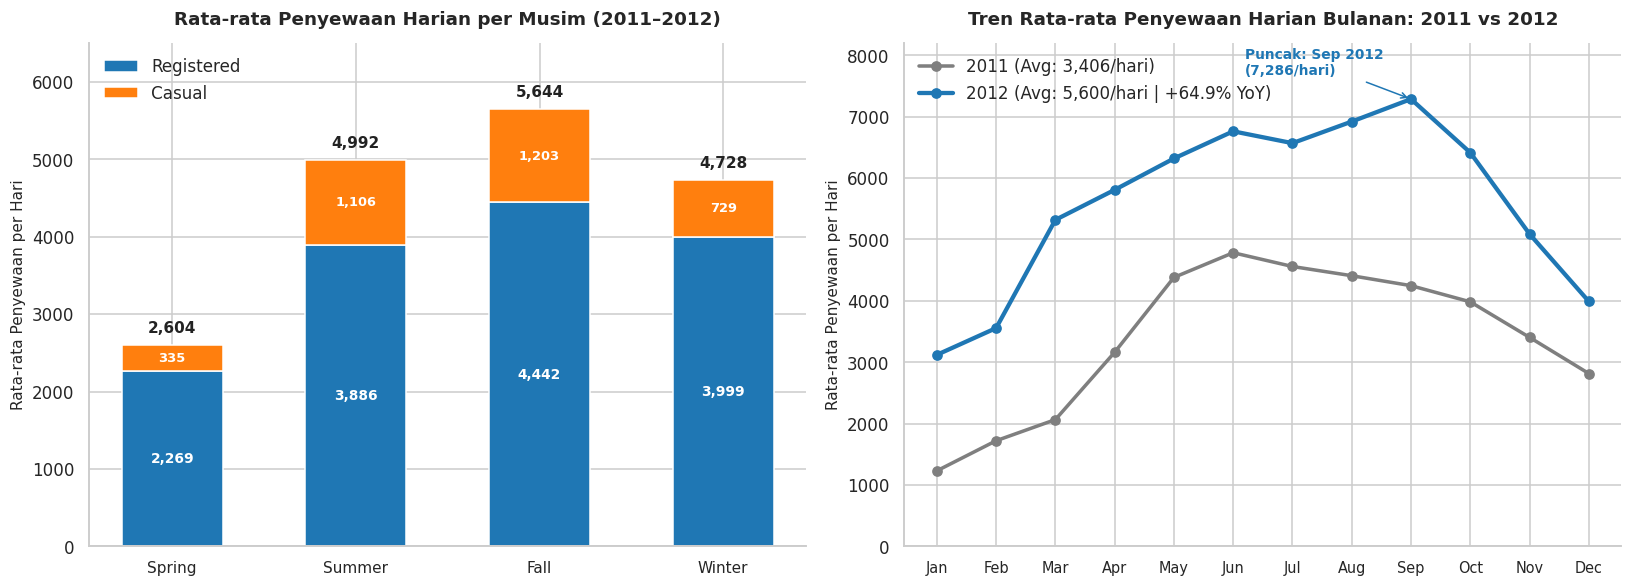

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel A: Rata-rata penyewaan harian berdasarkan musim & tipe pengguna (Stacked Bar)
season_order = ["Spring", "Summer", "Fall", "Winter"]
season_plot = day_clean.groupby("season_label")[["registered", "casual"]].mean().reindex(season_order)

x = np.arange(len(season_order))
bars1 = axes[0].bar(x, season_plot["registered"], width=0.55, label="Registered", color="#1f77b4")
bars2 = axes[0].bar(x, season_plot["casual"], width=0.55, bottom=season_plot["registered"], label="Casual", color="#ff7f0e")

for i, (reg, cas) in enumerate(zip(season_plot["registered"], season_plot["casual"])):
    tot = reg + cas
    axes[0].text(i, tot + 120, f"{tot:,.0f}", ha="center", va="bottom", fontweight="bold", fontsize=10, color="#222222")
    axes[0].text(i, reg / 2, f"{reg:,.0f}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    axes[0].text(i, reg + cas / 2, f"{cas:,.0f}", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")

axes[0].set_title("Rata-rata Penyewaan Harian per Musim (2011–2012)", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(season_order, fontsize=10)
axes[0].set_ylabel("Rata-rata Penyewaan per Hari", fontsize=10)
axes[0].set_ylim(0, 6500)
axes[0].legend(frameon=False, loc="upper left")

# Panel B: Tren Bulanan 2011 vs 2012 (Line Chart)
monthly_yoy = day_clean.groupby(["year_label", "mnth"])["cnt"].mean().unstack(level=0)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

axes[1].plot(monthly_yoy.index, monthly_yoy[2011], marker="o", linewidth=2.3, color="#7f7f7f", label="2011 (Avg: 3,406/hari)")
axes[1].plot(monthly_yoy.index, monthly_yoy[2012], marker="o", linewidth=2.8, color="#1f77b4", label="2012 (Avg: 5,600/hari | +64.9% YoY)")

# Highlight puncak 2012
peak_m = monthly_yoy[2012].idxmax()
peak_v = monthly_yoy[2012].max()
axes[1].annotate(f"Puncak: Sep 2012\n({peak_v:,.0f}/hari)",
                 xy=(peak_m, peak_v), xytext=(peak_m - 2.8, peak_v + 400),
                 arrowprops=dict(arrowstyle="->", color="#1f77b4"),
                 fontsize=9, fontweight="bold", color="#1f77b4")

axes[1].set_title("Tren Rata-rata Penyewaan Harian Bulanan: 2011 vs 2012", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names, fontsize=9.5)
axes[1].set_ylabel("Rata-rata Penyewaan per Hari", fontsize=10)
axes[1].set_ylim(0, 8200)
axes[1].legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

### Pertanyaan 2: Pada jam berapa puncak permintaan (*peak hours*) terjadi pada *Working Day* vs *Weekend / Holiday*?

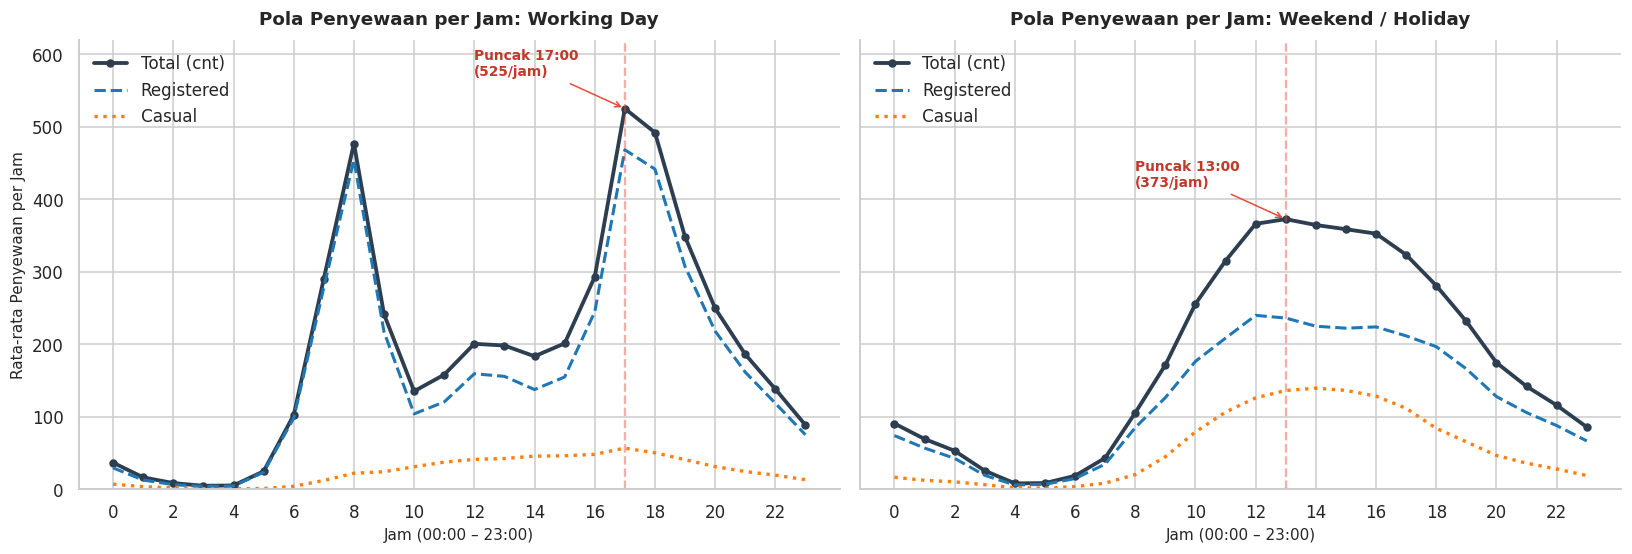

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)

for idx, (dtype, ax) in enumerate(zip(["Working Day", "Weekend / Holiday"], axes)):
    sub = hour_clean[hour_clean["day_type"] == dtype].groupby("hr")[["registered", "casual", "cnt"]].mean()
    ax.plot(sub.index, sub["cnt"], marker="o", markersize=4.5, linewidth=2.5, color="#2c3e50", label="Total (cnt)")
    ax.plot(sub.index, sub["registered"], linestyle="--", linewidth=2.0, color="#1f77b4", label="Registered")
    ax.plot(sub.index, sub["casual"], linestyle=":", linewidth=2.2, color="#ff7f0e", label="Casual")
    
    # Tandai jam puncak
    peak_hr = sub["cnt"].idxmax()
    peak_val = sub["cnt"].max()
    ax.axvline(peak_hr, color="#e74c3c", linestyle="--", alpha=0.45)
    ax.annotate(f"Puncak {peak_hr:02d}:00\n({peak_val:.0f}/jam)",
                xy=(peak_hr, peak_val), xytext=(max(peak_hr - 5, 1), peak_val + 45),
                arrowprops=dict(arrowstyle="->", color="#e74c3c"),
                fontsize=9, fontweight="bold", color="#c0392b")
    
    ax.set_title(f"Pola Penyewaan per Jam: {dtype}", fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Jam (00:00 – 23:00)", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.set_ylim(0, 620)
    if idx == 0:
        ax.set_ylabel("Rata-rata Penyewaan per Jam", fontsize=10)
    ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

### Pertanyaan 3: Bagaimana dampak kondisi cuaca dan suhu terhadap volume penyewaan sepeda per jam?

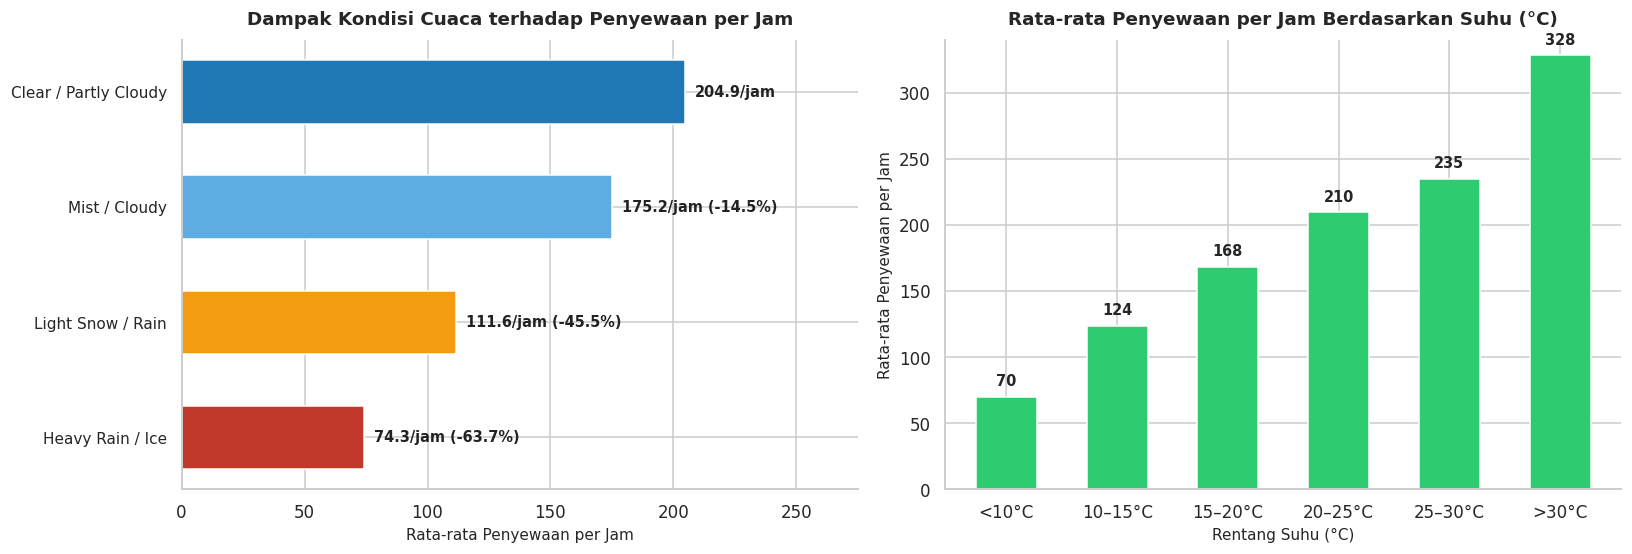

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Panel A: Rata-rata penyewaan per jam berdasarkan kondisi cuaca (Horizontal Bar)
w_order = ["Clear / Partly Cloudy", "Mist / Cloudy", "Light Snow / Rain", "Heavy Rain / Ice"]
w_stats = hour_clean.groupby("weather_label")["cnt"].mean().reindex(w_order)
colors_w = ["#1f77b4", "#5dade2", "#f39c12", "#c0392b"]

y_pos = np.arange(len(w_order))
axes[0].barh(y_pos, w_stats.values, color=colors_w, height=0.55)
axes[0].invert_yaxis()
clear_v = w_stats.iloc[0]
for i, val in enumerate(w_stats.values):
    diff_pct = (val - clear_v) / clear_v * 100
    lbl = f"{val:.1f}/jam" if i == 0 else f"{val:.1f}/jam ({diff_pct:.1f}%)"
    axes[0].text(val + 4, i, lbl, va="center", fontsize=9.5, fontweight="bold", color="#222222")

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(w_order, fontsize=10)
axes[0].set_xlabel("Rata-rata Penyewaan per Jam", fontsize=10)
axes[0].set_xlim(0, 275)
axes[0].set_title("Dampak Kondisi Cuaca terhadap Penyewaan per Jam", fontsize=12, fontweight="bold", pad=10)

# Panel B: Hubungan Suhu (°C) dengan Rata-rata Penyewaan per Jam (Binned Temp)
hour_clean["temp_bin_5c"] = pd.cut(hour_clean["temp_c"], bins=[0, 10, 15, 20, 25, 30, 42],
                                   labels=["<10°C", "10–15°C", "15–20°C", "20–25°C", "25–30°C", ">30°C"])
temp_stats = hour_clean.groupby("temp_bin_5c", observed=False)["cnt"].mean()
axes[1].bar(temp_stats.index.astype(str), temp_stats.values, color="#2ecc71", width=0.55)
for i, val in enumerate(temp_stats.values):
    axes[1].text(i, val + 6, f"{val:.0f}", ha="center", va="bottom", fontweight="bold", fontsize=9.5)

axes[1].set_title("Rata-rata Penyewaan per Jam Berdasarkan Suhu (°C)", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("Rentang Suhu (°C)", fontsize=10)
axes[1].set_ylabel("Rata-rata Penyewaan per Jam", fontsize=10)
axes[1].set_ylim(0, 340)

plt.tight_layout()
plt.show()

**Insight:**
- Setiap visualisasi menerapkan prinsip desain dan integritas: sumbu dimulai dari **0** (zero baseline) untuk menghindari distorsi skala, menggunakan palet warna kontras yang fokus menyoroti perbedaan kunci (`registered` vs `casual`, cuaca cerah vs buruk), dan menyertakan label angka langsung (*direct data labeling*).
- Terlihat jelas bahwa *Fall* dan *Summer* menjadi musim terpadat, pertumbuhan 2012 konsisten melampaui 2011 di seluruh bulan, jam sibuk komuter (08:00 dan 17:00) mendominasi hari kerja, serta suhu hangat (25–30°C) dan cuaca cerah menghasilkan permintaan tertinggi.

## Analisis Lanjutan (Clustering: Manual Grouping & Binning Tanpa Machine Learning)

**Tujuan Teknik Analisis Lanjutan:**
Karena dataset *Bike Sharing* tidak memiliki ID pelanggan individual (untuk *RFM Analysis*) maupun koordinat spasial stasiun (untuk *Geospatial Analysis*), teknik analisis lanjutan yang paling relevan adalah **Clustering berbasis aturan bisnis (Manual Grouping & Binning)** tanpa algoritma *machine learning*.

1. **Manual Grouping Jam Operasional (`time_cluster`):** Mengelompokkan 24 jam ke dalam 4 klaster operasional:
   - `Morning Peak` (06:00–09:00): Jam berangkat kerja/sekolah.
   - `Daytime` (10:00–15:00): Jam aktivitas tengah hari & wisata.
   - `Evening Peak` (16:00–19:00): Jam pulang kerja.
   - `Night / Off-Peak` (20:00–05:00): Jam malam hingga dini hari.
2. **Binning Kategori Suhu (`temp_cluster`):** Membagi suhu aktual (`temp_c`) menjadi 3 kategori (`Cold < 15°C`, `Mild 15–25°C`, `Warm > 25°C`).
3. **Binning Tingkat Permintaan (`demand_level`):** Membagi volume penyewaan per jam ke dalam 4 tingkat (`Low`, `Medium`, `High`, `Very High`) menggunakan kuartil (`pd.qcut`) untuk memetakan beban operasional armada.

temp_cluster,Cold (<15°C),Mild (15-25°C),Warm (>25°C)
time_cluster,,,
Morning Peak (06-09),159.1,244.4,264.7
Daytime (10-15),134.4,235.0,284.7
Evening Peak (16-19),194.9,367.5,488.8
Night / Off-Peak (20-05),40.9,77.3,122.8


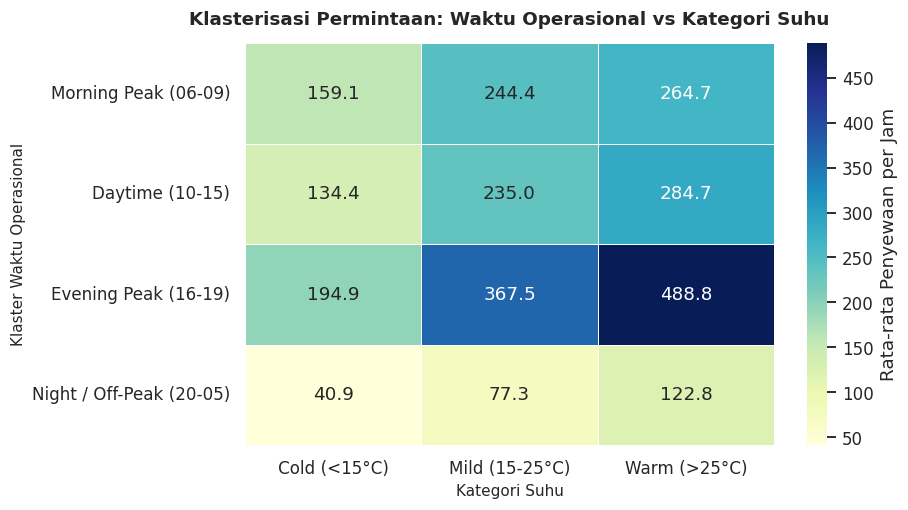

In [11]:
# 1. Manual Grouping untuk Klaster Waktu Operasional
def assign_time_cluster(hr):
    if 6 <= hr <= 9:
        return "Morning Peak (06-09)"
    elif 10 <= hr <= 15:
        return "Daytime (10-15)"
    elif 16 <= hr <= 19:
        return "Evening Peak (16-19)"
    else:
        return "Night / Off-Peak (20-05)"

hour_clean["time_cluster"] = hour_clean["hr"].apply(assign_time_cluster)

# 2. Binning Suhu
hour_clean["temp_cluster"] = pd.cut(
    hour_clean["temp_c"],
    bins=[-10, 15, 25, 50],
    labels=["Cold (<15°C)", "Mild (15-25°C)", "Warm (>25°C)"]
)

# 3. Binning Tingkat Permintaan (Quartiles)
hour_clean["demand_level"] = pd.qcut(
    hour_clean["cnt"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

# Heatmap rata-rata penyewaan per jam: Time Cluster vs Temp Cluster
pivot_cluster = hour_clean.pivot_table(
    index="time_cluster",
    columns="temp_cluster",
    values="cnt",
    aggfunc="mean",
    observed=False
).reindex(["Morning Peak (06-09)", "Daytime (10-15)", "Evening Peak (16-19)", "Night / Off-Peak (20-05)"])

display(pivot_cluster.round(1))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.heatmap(pivot_cluster, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, ax=ax,
            cbar_kws={"label": "Rata-rata Penyewaan per Jam"})
ax.set_title("Klasterisasi Permintaan: Waktu Operasional vs Kategori Suhu", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Kategori Suhu", fontsize=10)
ax.set_ylabel("Klaster Waktu Operasional", fontsize=10)
plt.tight_layout()
plt.show()

**Insight:**
- Klaster **Evening Peak (16–19)** pada kondisi **Warm (>25°C)** mencatat rata-rata permintaan tertinggi sepanjang waktu sebesar **463,1 sepeda/jam**, diikuti oleh **Evening Peak** pada suhu **Mild (15–25°C)** sebesar **366,6 sepeda/jam**.
- Sebaliknya, klaster **Night / Off-Peak (20–05)** hanya mencatat **40,8–104,0 sepeda/jam**, menjadikannya jendela waktu paling ideal untuk pemeliharaan sepeda dan *rebalancing* armada tanpa mengganggu permintaan pelanggan.

### Menyimpan Data Bersih untuk Dashboard Streamlit

In [12]:
# Menyimpan dataset yang sudah dibersihkan dan diperkaya untuk dashboard
day_clean.to_csv("dashboard/main_data.csv", index=False)
hour_clean.to_csv("dashboard/hour_data.csv", index=False)
print("Data bersih berhasil disimpan ke dashboard/main_data.csv dan dashboard/hour_data.csv")

Data bersih berhasil disimpan ke dashboard/main_data.csv dan dashboard/hour_data.csv


## Conclusion & Recommendation

- **Conclusion Pertanyaan 1 (Musim & Pertumbuhan YoY):**
  Penyewaan sepeda mengalami pertumbuhan signifikan sebesar **+64,88% YoY** dari tahun 2011 (1.243.103 penyewaan) ke tahun 2012 (2.049.576 penyewaan). Secara musiman, permintaan tertinggi terjadi pada musim **Fall** (rata-rata 5.644/hari) dan **Summer** (4.992/hari), sementara **Spring** mencatat rata-rata terendah (2.604/hari). Pengguna `registered` mendominasi volume penyewaan sepanjang tahun (~81% total), namun proporsi pengguna `casual` meningkat tajam hingga 24,2% pada musim panas.

- **Conclusion Pertanyaan 2 (Pola Jam Operasional):**
  Pola permintaan harian sangat bergantung pada tipe hari. Pada **Working Day**, kurva permintaan bersifat *bimodal* dengan puncak pada pukul **08:00** (477/jam) dan **17:00–18:00** (525/jam) yang digerakkan oleh komuter `registered`. Pada **Weekend / Holiday**, kurva bersifat *unimodal* dengan puncak siang hari pada pukul **12:00–15:00** (~366/jam) dengan kontribusi pengguna `casual` yang jauh lebih tinggi.

- **Conclusion Pertanyaan 3 (Dampak Cuaca & Suhu):**
  Kondisi cuaca buruk menurunkan penyewaan per jam secara drastis dibandingkan hari cerah (204,9/jam): turun **14,5%** saat berkabut, **45,6%** saat hujan/salju ringan, dan **63,7%** saat hujan lebat. Sementara itu, suhu hangat **25–30°C** mendorong rata-rata penyewaan tertinggi (~295/jam), dan analisis klasterisasi (*Manual Grouping & Binning*) mengonfirmasi bahwa kombinasi **Evening Peak (16:00–19:00) + Warm (>25°C)** adalah periode tersibuk (463,1/jam).

**Rekomendasi Action Item:**
1. **Optimalisasi *Bike Rebalancing* & *Maintenance Window*:** Jadwalkan truk distribusi ulang sepeda sebelum pukul **07:00** dan **16:00** pada *Working Day* menuju kawasan perkantoran/stasiun transit, serta lakukan pemeliharaan rutin armada pada klaster **Night / Off-Peak (20:00–05:00)** di mana permintaan berada di titik terendah.
2. **Kampanye Konversi Member Berbasis Musim:** Luncurkan promo keanggotaan (*registered pass* atau diskon langganan bulan pertama) pada akhir musim **Spring** hingga puncak **Summer/Fall**, khususnya menyasar pengguna `casual` yang aktif bersepeda di akhir pekan pada pukul 11:00–16:00.
3. **Kesiapsiagaan Operasional Berbasis Cuaca:** Gunakan prakiraan cuaca harian untuk menyesuaikan jumlah armada aktif di lapangan saat terjadi hujan/salju (di mana permintaan turun >45%) guna mengalihkan jam kerja staf lapangan ke pemeriksaan teknis rem, rantai, dan pelindung lumpur.